## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch
from sklearn.manifold import TSNE

# dataset helper
from helper import get_wl_point_obs, plot_shred_reconstruction, extract_water_level_measurements, align_ds

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import ROMDataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.train import lagged_fit, lagged_evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

np.random.seed(42)

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Results Tuning

In [4]:
dataframe_errors = pd.read_csv("results_df/notebook7/dataframe_errors_all2.csv", index_col=0)
print("\nFinal comparison of all models, ordered by test MRE:")
dataframe_errors = dataframe_errors.sort_values(by="test-mre")
display(dataframe_errors)


Final comparison of all models, ordered by test MRE:


,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
model,,,,,,,
(mSHRED): TR+cnn,"Lagged_training (w=0.7, k=16)",0.003401,0.005074,0.003164,0.118862,0.133322,0.115688
(mSHRED): TR+cnn,"Lagged_training (w=0.5, k=12)",0.003341,0.005103,0.003195,0.117868,0.133682,0.115747
(mSHRED): TR+cnn,"Lagged_training (w=0.8, k=16)",0.003476,0.004995,0.003175,0.119815,0.133521,0.115812
(mSHRED): TR+cnn,"Lagged_training (w=0.4, k=4)",0.003558,0.005100,0.003172,0.121419,0.134063,0.116187
(mSHRED): TR+cnn,"Lagged_training (w=0.6, k=4)",0.003528,0.005074,0.003185,0.120757,0.133762,0.116195
...,...,...,...,...,...,...,...
(mSHRED): TR+cnn,"Lagged_training (w=0.2, k=4)",0.003888,0.005174,0.003323,0.126664,0.136109,0.119458
(mSHRED): TR+cnn,"Lagged_training (w=0.4, k=16)",0.003950,0.005258,0.003337,0.127374,0.137112,0.119575
(mSHRED): TR+cnn,"Lagged_training (w=0.7, k=8)",0.003875,0.005168,0.003351,0.126518,0.136517,0.119766


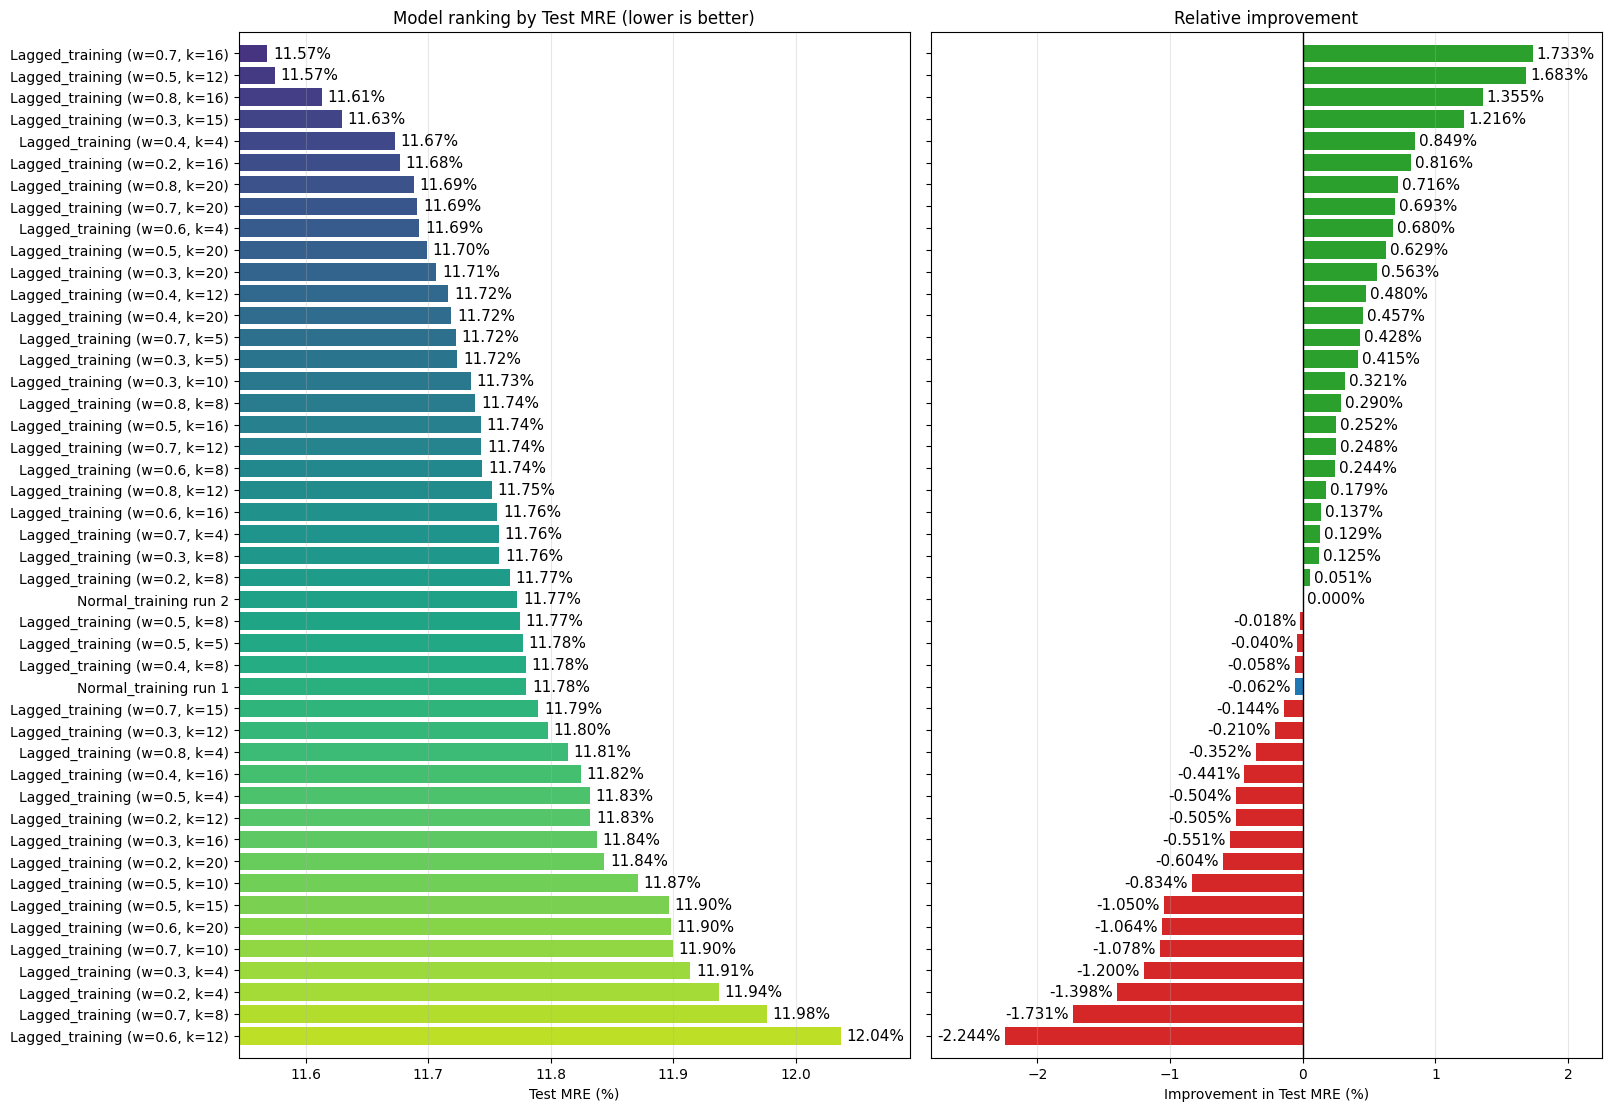

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Meaningful summary plot: ranking + improvement vs baseline
numeric_cols = dataframe_errors.select_dtypes(include=[np.number]).columns.tolist()
df_plot = dataframe_errors.groupby("type", as_index=False)[numeric_cols].mean()
df_plot = df_plot.sort_values("test-mre").reset_index(drop=True)

# Baseline = Normal_training (average if duplicates exist)
baseline_mask = df_plot["type"].str.contains("Normal_training", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

# Keeping height at 11 for a balanced look with the new padding
fig, axes = plt.subplots(1, 2, figsize=(16, 11), constrained_layout=True)

num_rows = len(df_plot)
y_positions = np.arange(num_rows)

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, num_rows))
axes[0].barh(y_positions, df_plot["test-mre_%"], color=colors)
axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(df_plot["type"])
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)

# ADJUSTMENT: Changed padding from 0.5 to 1.0 to add a subtle sliver of white space
axes[0].set_ylim(num_rows, -1.0)

# Dynamic x limits based on actual range
min_mre = df_plot["test-mre_%"].min()
max_mre = df_plot["test-mre_%"].max()
axes[0].set_xlim(min_mre - (max_mre - min_mre) * 0.05, max_mre + (max_mre - min_mre) * 0.12)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + (max_mre - min_mre) * 0.01, i, f"{v:.2f}%", va="center", fontsize=11)

# --- Right: Improvement ---
imp_colors = ["tab:blue" if ("Normal_training" in t) else ("tab:green" if x >= 0 else "tab:red") for t, x in zip(df_plot["type"], df_plot["improvement_vs_T0_%"])]
axes[1].barh(y_positions, df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)

# ADJUSTMENT: Mirror the exact same slight padding on the right plot
axes[1].set_ylim(num_rows, -1.0)

# Balanced x limits with proper padding for text labels
min_imp = df_plot["improvement_vs_T0_%"].min()
max_imp = df_plot["improvement_vs_T0_%"].max()
axes[1].set_xlim(min_imp * 1.25, max_imp * 1.3)

axes[1].set_yticklabels([])
axes[1].set_yticks(y_positions)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    if v >= 0:
        axes[1].text(v + 0.03, i, f"{v:.3f}%", va="center", ha="left", fontsize=11)
    else:
        axes[1].text(v - 0.03, i, f"{v:.3f}%", va="center", ha="right", fontsize=11)

plt.show()

font_size usato: 20.0 pt  |  larghezza: 26.02 in


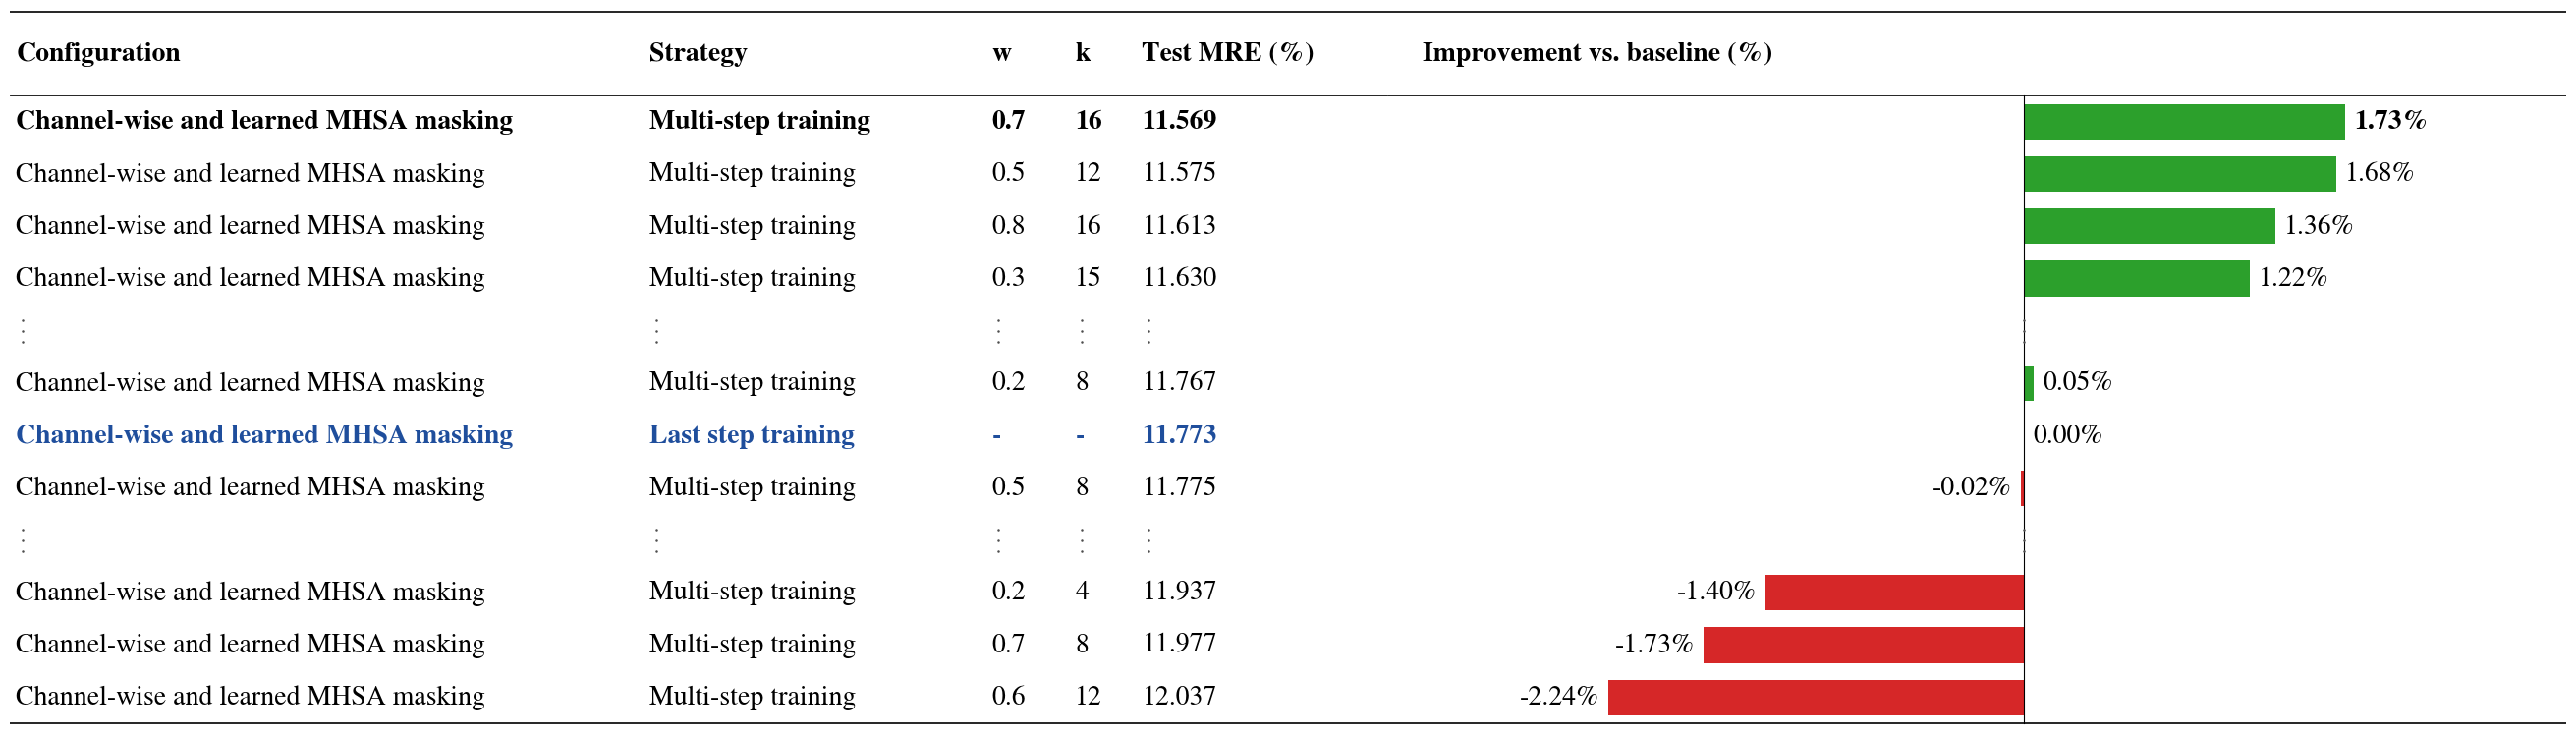

In [6]:
import re
import numpy as np
import matplotlib.pyplot as plt

PAPER_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

_PAT = re.compile(r"^(.*?)\s*\(w=([\d.]+),\s*k=(\d+)\)\s*$")


STRATEGY_MAP = {
    "Normal_training": "Last step training",
    "Lagged_training": "Multi-step training",
}


def parse_type(t):
    """'Lagged_training (w=0.7, k=16)' -> ('Multi-step training', '0.7', '16')."""
    m = _PAT.match(t)
    if m:
        return STRATEGY_MAP.get(m.group(1), m.group(1)), m.group(2), m.group(3)
    base = t.split(" run")[0].strip()          # 'Normal_training run 2' -> 'Normal_training'
    return STRATEGY_MAP.get(base, base.replace("_", " ")), "-", "-"


def _vdots(ax, x, y, color="0.3", ms=1.8, gap=0.2):
    ax.plot([x] * 3, [y - gap, y, y + gap], linestyle="none", marker="o",
            markersize=ms, color=color, markeredgewidth=0, clip_on=False)


def select_rows(df, n_top=6, n_bottom=6, n_around=2):
    """
    df ordinato per test-mre crescente. Prime n_top righe, poi il blocco centrato
    sulla baseline (n_around sopra + baseline + n_around sotto), poi le ultime n_bottom.
    None = separatore (puntini).
    """
    recs = df.to_dict("records")
    n = len(recs)
    cand = [i for i, r in enumerate(recs) if "Normal_training" in r["type"]]
    if not cand:
        cand = [n // 2]
    # baseline di riferimento = quella con improvement ~ 0
    b = min(cand, key=lambda i: abs(recs[i]["improvement_vs_T0_%"]))
    lo = max(b - n_around, n_top)
    hi = min(b + n_around + 1, n - n_bottom)
    return recs[:n_top] + [None] + recs[lo:hi] + [None] + recs[-n_bottom:]


def plot_ranking_table(df_plot, n_top=6, n_bottom=6, n_around=2,
                       configuration="Channel-wise and learned MHSA masking",
                       fname="ranking_table",
                       target_width_in=7.0,
                       font_size=None,
                       bar_header="Improvement vs. baseline (%)",
                       bar_color="#2ca02c", neg_color="#d62728",
                       baseline_color="#1f4e9c",
                       char_k=0.0080, bar_k=0.60, col_pad=2.2,
                       save_formats=("pdf", "png"), dpi=600, show=True):
    """
    df_plot: colonne 'type', 'test-mre_%', 'improvement_vs_T0_%'.
    Tabella (Strategy | w | k | Test MRE) + barre di miglioramento %.
    Includila in LaTeX con width=\\textwidth: il font risultante e' quello reale.
    """
    df = df_plot.sort_values("test-mre_%").reset_index(drop=True).copy()
    rows = select_rows(df, n_top, n_bottom, n_around)
    m = len(rows)
    is_base = [r is not None and "Normal_training" in r["type"] for r in rows]

    headers = ["Configuration", "Strategy", "w", "k", "Test MRE (%)"]
    cells = []
    for r in rows:
        if r is None:
            cells.append(None)
        else:
            s, w, k = parse_type(r["type"])
            cells.append([configuration, s, w, k, f"{r['test-mre_%']:.3f}"])

    # ---- larghezze colonne (in caratteri) ----
    widths = []
    for j, h in enumerate(headers):
        txt = [len(c[j]) for c in cells if c is not None]
        h_len = max(len(line) for line in h.split("\n"))
        widths.append(max([h_len * 1.15] + [t * 1.03 for t in txt]) + col_pad)
    xs = np.cumsum([0] + widths)
    total = xs[-1]
    lefts = xs[:-1] + 0.4

    # ---- font auto-fit ----
    if font_size is None:
        font_size = target_width_in / (total * char_k + bar_k)
    char_in = char_k * font_size
    bar_width_in = bar_k * font_size
    table_w = total * char_in
    row_h = font_size * 1.85 / 72
    head_rows = 1.6
    fig_h = row_h * (m + head_rows + 0.6)

    rc = dict(PAPER_RC, **{"font.size": font_size})
    with plt.rc_context(rc):
        fig, (ax_t, ax_b) = plt.subplots(
            1, 2, figsize=(table_w + bar_width_in, fig_h), sharey=True,
            gridspec_kw={"width_ratios": [table_w, bar_width_in], "wspace": 0.0},
        )
        y = np.arange(m)
        Y_MID = -0.5
        Y_TOP = Y_MID - head_rows
        Y_HEAD = (Y_TOP + Y_MID) / 2
        Y_BOT = m - 0.5
        RULE_THICK, RULE_THIN = 1.2, 0.6

        # ---- tabella ----
        ax_t.set_xlim(0, total)
        ax_t.set_ylim(Y_BOT + 0.05, Y_TOP - 0.05)
        ax_t.axis("off")
        for j, h in enumerate(headers):
            ax_t.text(lefts[j], Y_HEAD, h, ha="left", va="center",
                      fontweight="bold", linespacing=1.05)
        ax_t.axhline(Y_TOP, color="black", lw=RULE_THICK)
        ax_t.axhline(Y_MID, color="black", lw=RULE_THIN)
        ax_t.axhline(Y_BOT, color="black", lw=RULE_THICK)

        for i, (r, c, b) in enumerate(zip(rows, cells, is_base)):
            if r is None:
                for j in range(len(headers)):
                    _vdots(ax_t, lefts[j] + 0.4, i)
                continue
            for j, t in enumerate(c):
                ax_t.text(lefts[j], i, t, ha="left", va="center",
                          fontweight="bold" if (i == 0 or b) else "normal",
                          color=baseline_color if b else "black")

        # ---- barre ----
        vals = np.array([np.nan if r is None else r["improvement_vs_T0_%"] for r in rows])
        vmax, vmin = np.nanmax(vals), min(0.0, np.nanmin(vals))
        span = vmax - vmin
        xmin = vmin - (0.30 * span if vmin < 0 else 0.02 * span)
        xmax = vmax + 0.30 * span
        ax_b.set_xlim(xmin, xmax)

        colors = [("none" if r is None else baseline_color if b
                   else bar_color if v >= 0 else neg_color)
                  for r, b, v in zip(rows, is_base, vals)]
        ax_b.barh(y, np.nan_to_num(vals, nan=0.0), color=colors, height=0.68)
        ax_b.plot([0, 0], [Y_MID, Y_BOT], color="black", lw=0.8)

        ax_b.text(0.03, Y_HEAD, bar_header, transform=ax_b.get_yaxis_transform(),
                  ha="left", va="center", fontweight="bold", linespacing=1.05)
        ax_b.axhline(Y_TOP, color="black", lw=RULE_THICK)
        ax_b.axhline(Y_MID, color="black", lw=RULE_THIN)
        ax_b.axhline(Y_BOT, color="black", lw=RULE_THICK)

        for i, (r, v) in enumerate(zip(rows, vals)):
            if r is None:
                _vdots(ax_b, 0, i)
                continue
            ax_b.text(v + (0.012 if v >= 0 else -0.012) * span, i, f"{v:.2f}%",
                      ha="left" if v >= 0 else "right", va="center",
                      fontweight="bold" if i == 0 else "normal")

        for s in ax_b.spines.values():
            s.set_visible(False)
        ax_b.set_xticks([])
        ax_b.set_yticks([])

        fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
        for ext in save_formats:
            fig.savefig(f"{fname}.{ext}", dpi=dpi, bbox_inches="tight", pad_inches=0.03)
        print(f"font_size usato: {font_size:.1f} pt  |  larghezza: {table_w + bar_width_in:.2f} in")
        if show:
            plt.show()
        plt.close(fig)


# ----------------------------------------------------------------------------
# Preparazione dati (identica al tuo codice) + chiamata
# ----------------------------------------------------------------------------
numeric_cols = dataframe_errors.select_dtypes(include=[np.number]).columns.tolist()
df_plot = dataframe_errors.groupby("type", as_index=False)[numeric_cols].mean()
df_plot = df_plot.sort_values("test-mre").reset_index(drop=True)

baseline_mask = df_plot["type"].str.contains("Normal_training", regex=False)
baseline_test_mre = (df_plot.loc[baseline_mask, "test-mre"].iloc[0]
                     if baseline_mask.any() else df_plot["test-mre"].max())

df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

plot_results_table = plot_ranking_table  # alias, se preferisci il vecchio nome
plot_ranking_table(df_plot, n_top=4, n_bottom=3, n_around=1,
                   fname="HYDRO_9_lagged_tuning", font_size=20)
# LaTeX: \includegraphics[width=\textwidth]{ranking_table.pdf}

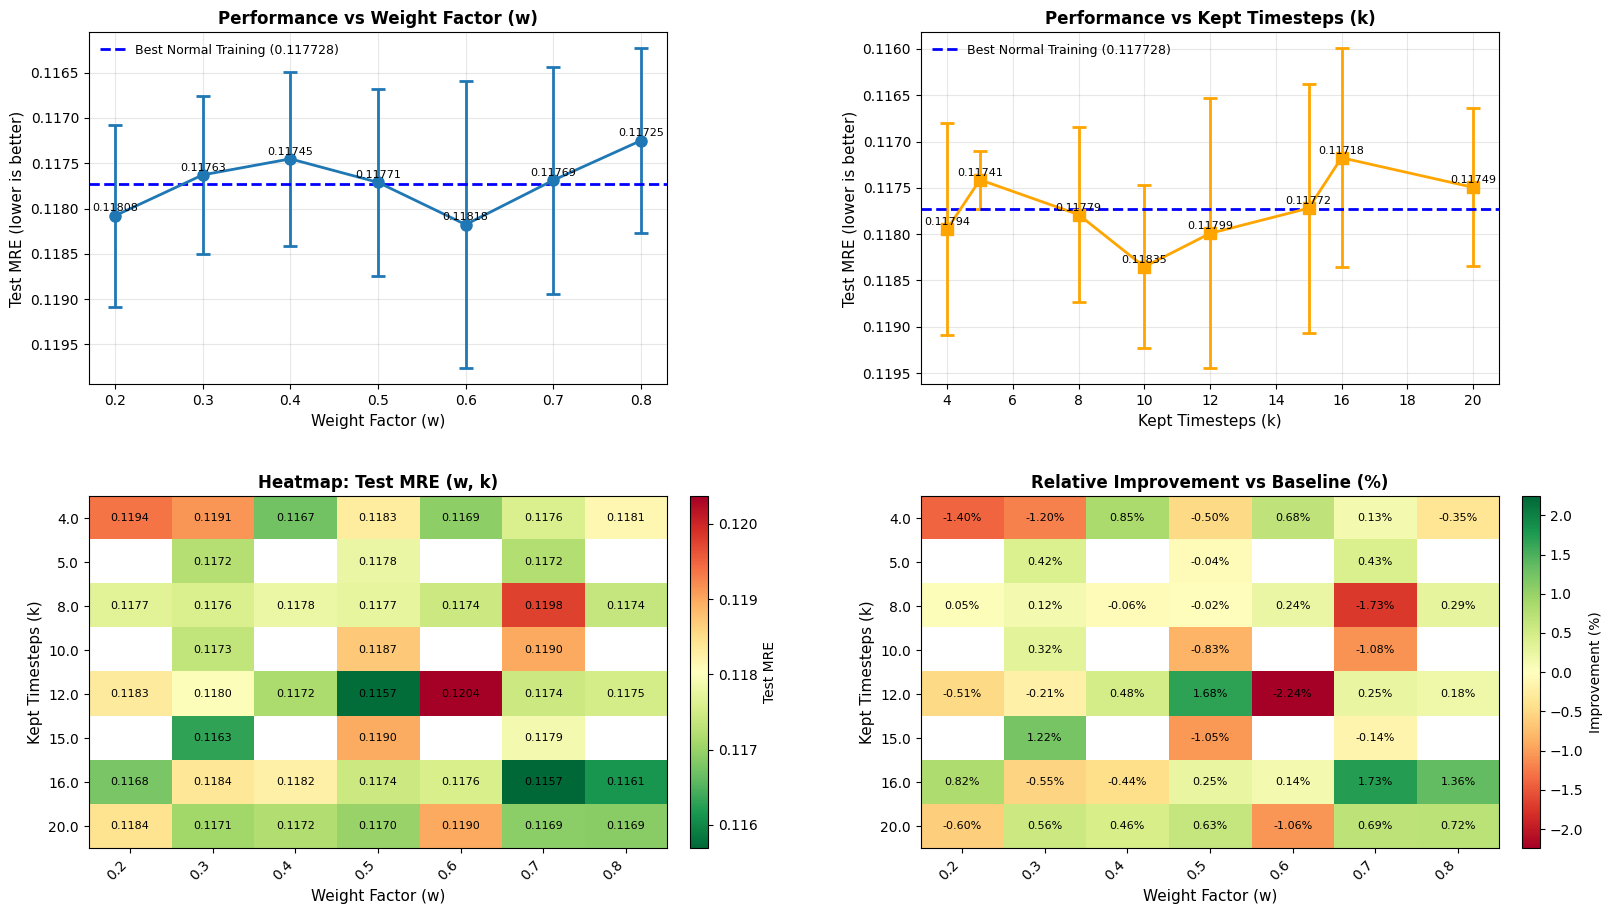

In [7]:
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Extract w and k values from lagged training results
df_tuning = dataframe_errors[dataframe_errors["type"].str.contains("Lagged_training \(w=", regex=True)].copy()

# Parse w and k from type string
def extract_w_k(type_str):
    match = re.search(r"w=([\d.]+),\s*k=(\d+)", type_str)
    if match:
        return float(match.group(1)), int(match.group(2))
    return None, None

df_tuning[["w", "k"]] = df_tuning["type"].apply(lambda x: pd.Series(extract_w_k(x)))

# Get best normal training baseline
normal_mask = dataframe_errors["type"].str.contains("Normal_training", regex=False)
best_normal_test_mre = dataframe_errors.loc[normal_mask, "test-mre"].min() if normal_mask.any() else None

# --- Plot Setup ---
fig, axes = plt.subplots(2, 2, figsize=(16, 9), constrained_layout=True)
axes = axes.flatten()
fig.set_constrained_layout_pads(w_pad=0.03, h_pad=0.03, wspace=0.08, hspace=0.10)

# --- Plot 1: w vs performance (aggregated across k) ---
w_perf = df_tuning.groupby("w")["test-mre"].agg(["mean", "std"])
axes[0].errorbar(w_perf.index, w_perf["mean"], yerr=w_perf["std"], marker="o", linewidth=2, markersize=8, capsize=5, capthick=2)
if best_normal_test_mre is not None:
    axes[0].axhline(best_normal_test_mre, color="blue", linestyle="--", linewidth=2, label=f"Best Normal Training ({best_normal_test_mre:.6f})")
axes[0].set_xlabel("Weight Factor (w)", fontsize=11)
axes[0].set_ylabel("Test MRE (lower is better)", fontsize=11)
axes[0].set_title("Performance vs Weight Factor (w)", fontsize=12, fontweight="bold")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=9, loc="best", frameon=False)

# FIX: Invert y-axis so lower MRE values are visually at the top
axes[0].invert_yaxis()

for w_val, mean_val in zip(w_perf.index, w_perf["mean"]):
    axes[0].text(w_val, mean_val - w_perf["std"].max() * 0.03, f"{mean_val:.5f}", ha="center", fontsize=8)

# --- Plot 2: k vs performance (aggregated across w) ---
k_perf = df_tuning.groupby("k")["test-mre"].agg(["mean", "std"])
axes[1].errorbar(k_perf.index, k_perf["mean"], yerr=k_perf["std"], marker="s", linewidth=2, markersize=8, capsize=5, capthick=2, color="orange")
if best_normal_test_mre is not None:
    axes[1].axhline(best_normal_test_mre, color="blue", linestyle="--", linewidth=2, label=f"Best Normal Training ({best_normal_test_mre:.6f})")
axes[1].set_xlabel("Kept Timesteps (k)", fontsize=11)
axes[1].set_ylabel("Test MRE (lower is better)", fontsize=11)
axes[1].set_title("Performance vs Kept Timesteps (k)", fontsize=12, fontweight="bold")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=9, loc="best", frameon=False)

# FIX: Invert y-axis so lower MRE values are visually at the top
axes[1].invert_yaxis()

for k_val, mean_val in zip(k_perf.index, k_perf["mean"]):
    axes[1].text(k_val, mean_val - k_perf["std"].max() * 0.03, f"{mean_val:.5f}", ha="center", fontsize=8)

# --- Plot 3: Heatmap of w-k combinations (Test MRE) ---
pivot_table = df_tuning.pivot_table(values="test-mre", index="k", columns="w", aggfunc="mean")
pivot_table = pivot_table.sort_index(ascending=True)
masked_data = np.ma.masked_invalid(pivot_table.values)

im = axes[2].imshow(masked_data, cmap="RdYlGn_r", aspect="auto")
axes[2].set_xticks(range(len(pivot_table.columns)))
axes[2].set_yticks(range(len(pivot_table.index)))
axes[2].set_xticklabels([f"{w:.1f}" for w in pivot_table.columns], rotation=45, ha="right")
axes[2].set_yticklabels([f"{k}" for k in pivot_table.index])
axes[2].set_xlabel("Weight Factor (w)", fontsize=11)
axes[2].set_ylabel("Kept Timesteps (k)", fontsize=11)
axes[2].set_title("Heatmap: Test MRE (w, k)", fontsize=12, fontweight="bold")

for i in range(len(pivot_table.index)):
    for j in range(len(pivot_table.columns)):
        val = pivot_table.values[i, j]
        if not np.isnan(val):
            axes[2].text(j, i, f"{val:.4f}", ha="center", va="center", fontsize=8, color="black")

cbar = fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
cbar.set_label("Test MRE", fontsize=10)

# --- Plot 4: Heatmap of relative improvement vs baseline ---
if best_normal_test_mre is not None:
    df_tuning["improvement"] = (best_normal_test_mre - df_tuning["test-mre"]) / best_normal_test_mre * 100
    
    improvement_pivot = df_tuning.pivot_table(values="improvement", index="k", columns="w", aggfunc="mean")
    improvement_pivot = improvement_pivot.sort_index(ascending=True)
    
    masked_improvement = np.ma.masked_invalid(improvement_pivot.values)
    max_abs_improvement = np.nanmax(np.abs(improvement_pivot.values))
    
    im4 = axes[3].imshow(masked_improvement, cmap="RdYlGn", aspect="auto", 
                         vmin=-max_abs_improvement, vmax=max_abs_improvement)
    axes[3].set_xticks(range(len(improvement_pivot.columns)))
    axes[3].set_yticks(range(len(improvement_pivot.index)))
    axes[3].set_xticklabels([f"{w:.1f}" for w in improvement_pivot.columns], rotation=45, ha="right")
    axes[3].set_yticklabels([f"{k}" for k in improvement_pivot.index])
    axes[3].set_xlabel("Weight Factor (w)", fontsize=11)
    axes[3].set_ylabel("Kept Timesteps (k)", fontsize=11)
    axes[3].set_title("Relative Improvement vs Baseline (%)", fontsize=12, fontweight="bold")
    
    for i in range(len(improvement_pivot.index)):
        for j in range(len(improvement_pivot.columns)):
            val = improvement_pivot.values[i, j]
            if not np.isnan(val):
                axes[3].text(j, i, f"{val:.2f}%", ha="center", va="center", fontsize=8, color="black")
    
    cbar4 = fig.colorbar(im4, ax=axes[3], fraction=0.046, pad=0.04)
    cbar4.set_label("Improvement (%)", fontsize=10)

plt.show()

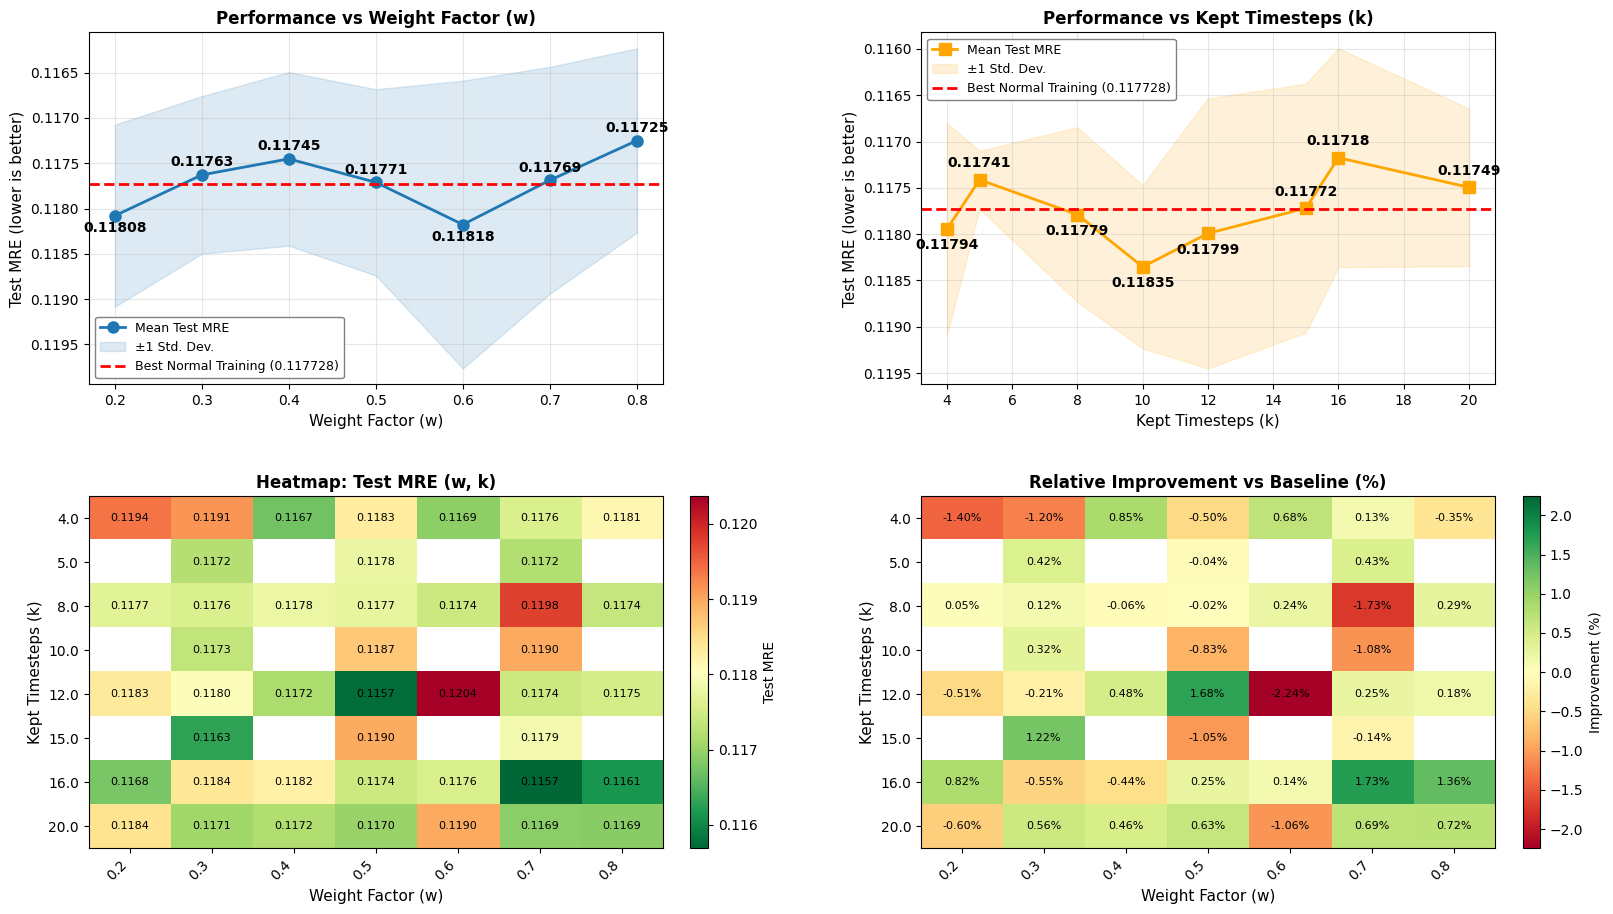

In [8]:
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Extract w and k values from lagged training results
df_tuning = dataframe_errors[dataframe_errors["type"].str.contains("Lagged_training \(w=", regex=True)].copy()

# Parse w and k from type string
def extract_w_k(type_str):
    match = re.search(r"w=([\d.]+),\s*k=(\d+)", type_str)
    if match:
        return float(match.group(1)), int(match.group(2))
    return None, None

df_tuning[["w", "k"]] = df_tuning["type"].apply(lambda x: pd.Series(extract_w_k(x)))

# Get best normal training baseline
normal_mask = dataframe_errors["type"].str.contains("Normal_training", regex=False)
best_normal_test_mre = dataframe_errors.loc[normal_mask, "test-mre"].min() if normal_mask.any() else None

# --- Plot Setup ---
fig, axes = plt.subplots(2, 2, figsize=(16, 9), constrained_layout=True)
axes = axes.flatten()
fig.set_constrained_layout_pads(w_pad=0.03, h_pad=0.03, wspace=0.08, hspace=0.10)

# --- Plot 1: w vs performance (aggregated across k) ---
w_perf = df_tuning.groupby("w")["test-mre"].agg(["mean", "std"])

axes[0].plot(w_perf.index, w_perf["mean"], marker="o", linewidth=2, markersize=8, color="tab:blue", label="Mean Test MRE")
axes[0].fill_between(w_perf.index, w_perf["mean"] - w_perf["std"], w_perf["mean"] + w_perf["std"], 
                     color="tab:blue", alpha=0.15, label="±1 Std. Dev.")

if best_normal_test_mre is not None:
    axes[0].axhline(best_normal_test_mre, color="red", linestyle="--", linewidth=2, label=f"Best Normal Training ({best_normal_test_mre:.6f})")

axes[0].set_xlabel("Weight Factor (w)", fontsize=11)
axes[0].set_ylabel("Test MRE (lower is better)", fontsize=11)
axes[0].set_title("Performance vs Weight Factor (w)", fontsize=12, fontweight="bold")
axes[0].grid(alpha=0.3)

# FIX: Added solid white background with a subtle border to the legend
axes[0].legend(fontsize=9, loc="best", frameon=True, facecolor="white", edgecolor="gray", framealpha=1.0)
axes[0].invert_yaxis()

offset_w = (w_perf["mean"].max() - w_perf["mean"].min()) * 0.15
for w_val, mean_val in zip(w_perf.index, w_perf["mean"]):
    if best_normal_test_mre is not None and mean_val < best_normal_test_mre:
        y_pos = mean_val - offset_w
    else:
        y_pos = mean_val + offset_w
    axes[0].text(w_val, y_pos, f"{mean_val:.5f}", ha="center", va="center", fontsize=10, fontweight="bold")

# --- Plot 2: k vs performance (aggregated across w) ---
k_perf = df_tuning.groupby("k")["test-mre"].agg(["mean", "std"])

axes[1].plot(k_perf.index, k_perf["mean"], marker="s", linewidth=2, markersize=8, color="orange", label="Mean Test MRE")
axes[1].fill_between(k_perf.index, k_perf["mean"] - k_perf["std"], k_perf["mean"] + k_perf["std"], 
                     color="orange", alpha=0.15, label="±1 Std. Dev.")

if best_normal_test_mre is not None:
    axes[1].axhline(best_normal_test_mre, color="red", linestyle="--", linewidth=2, label=f"Best Normal Training ({best_normal_test_mre:.6f})")

axes[1].set_xlabel("Kept Timesteps (k)", fontsize=11)
axes[1].set_ylabel("Test MRE (lower is better)", fontsize=11)
axes[1].set_title("Performance vs Kept Timesteps (k)", fontsize=12, fontweight="bold")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=9, loc="best", frameon=True, facecolor="white", edgecolor="gray", framealpha=1.0)
axes[1].invert_yaxis()

# FIX: Added fontweight="bold" to match plot 1
offset_k = (k_perf["mean"].max() - k_perf["mean"].min()) * 0.15
for k_val, mean_val in zip(k_perf.index, k_perf["mean"]):
    if best_normal_test_mre is not None and mean_val < best_normal_test_mre:
        y_pos = mean_val - offset_k
    else:
        y_pos = mean_val + offset_k
    axes[1].text(k_val, y_pos, f"{mean_val:.5f}", ha="center", va="center", fontsize=10, fontweight="bold")

# --- Plot 3: Heatmap of w-k combinations (Test MRE) ---
pivot_table = df_tuning.pivot_table(values="test-mre", index="k", columns="w", aggfunc="mean")
pivot_table = pivot_table.sort_index(ascending=True)
masked_data = np.ma.masked_invalid(pivot_table.values)

im = axes[2].imshow(masked_data, cmap="RdYlGn_r", aspect="auto")
axes[2].set_xticks(range(len(pivot_table.columns)))
axes[2].set_yticks(range(len(pivot_table.index)))
axes[2].set_xticklabels([f"{w:.1f}" for w in pivot_table.columns], rotation=45, ha="right")
axes[2].set_yticklabels([f"{k}" for k in pivot_table.index])
axes[2].set_xlabel("Weight Factor (w)", fontsize=11)
axes[2].set_ylabel("Kept Timesteps (k)", fontsize=11)
axes[2].set_title("Heatmap: Test MRE (w, k)", fontsize=12, fontweight="bold")

for i in range(len(pivot_table.index)):
    for j in range(len(pivot_table.columns)):
        val = pivot_table.values[i, j]
        if not np.isnan(val):
            axes[2].text(j, i, f"{val:.4f}", ha="center", va="center", fontsize=8, color="black")

cbar = fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
cbar.set_label("Test MRE", fontsize=10)

# --- Plot 4: Heatmap of relative improvement vs baseline ---
if best_normal_test_mre is not None:
    df_tuning["improvement"] = (best_normal_test_mre - df_tuning["test-mre"]) / best_normal_test_mre * 100
    
    improvement_pivot = df_tuning.pivot_table(values="improvement", index="k", columns="w", aggfunc="mean")
    improvement_pivot = improvement_pivot.sort_index(ascending=True)
    
    masked_improvement = np.ma.masked_invalid(improvement_pivot.values)
    max_abs_improvement = np.nanmax(np.abs(improvement_pivot.values))
    
    im4 = axes[3].imshow(masked_improvement, cmap="RdYlGn", aspect="auto", 
                         vmin=-max_abs_improvement, vmax=max_abs_improvement)
    axes[3].set_xticks(range(len(improvement_pivot.columns)))
    axes[3].set_yticks(range(len(improvement_pivot.index)))
    axes[3].set_xticklabels([f"{w:.1f}" for w in improvement_pivot.columns], rotation=45, ha="right")
    axes[3].set_yticklabels([f"{k}" for k in improvement_pivot.index])
    axes[3].set_xlabel("Weight Factor (w)", fontsize=11)
    axes[3].set_ylabel("Kept Timesteps (k)", fontsize=11)
    axes[3].set_title("Relative Improvement vs Baseline (%)", fontsize=12, fontweight="bold")
    
    for i in range(len(improvement_pivot.index)):
        for j in range(len(improvement_pivot.columns)):
            val = improvement_pivot.values[i, j]
            if not np.isnan(val):
                axes[3].text(j, i, f"{val:.2f}%", ha="center", va="center", fontsize=8, color="black")
    
    cbar4 = fig.colorbar(im4, ax=axes[3], fraction=0.046, pad=0.04)
    cbar4.set_label("Improvement (%)", fontsize=10)

plt.show()

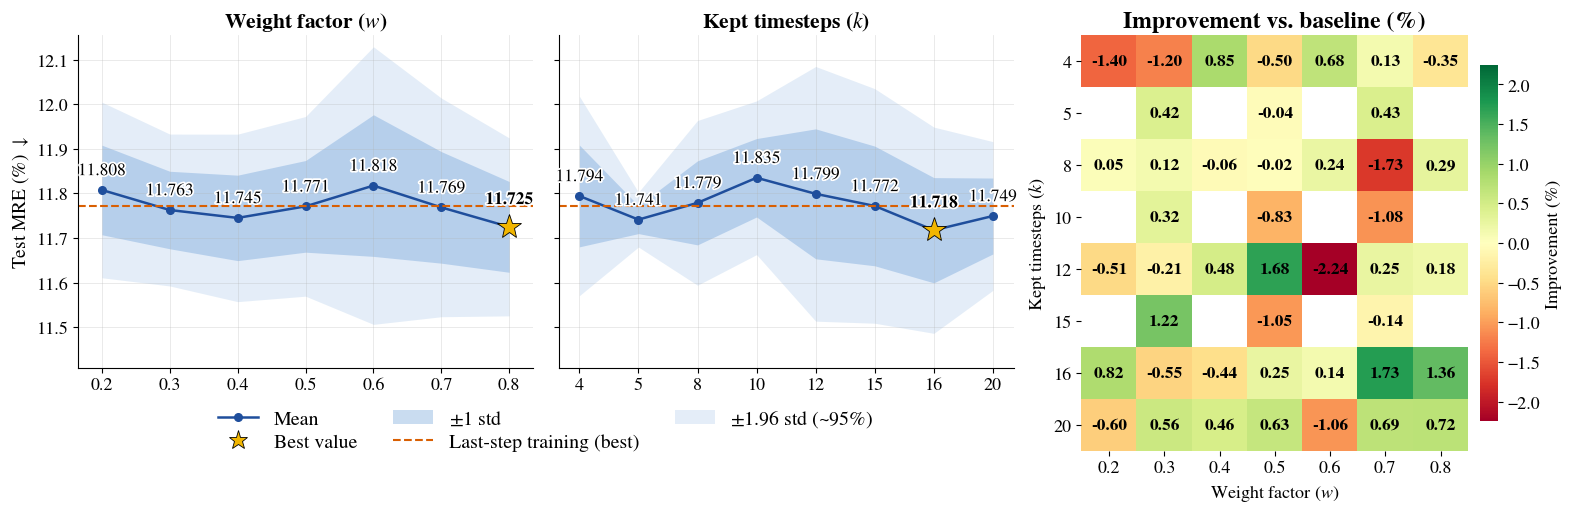

In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ----------------------------------------------------------------------------
# Stile (coerente con la tabella e con i marginal effects)
# ----------------------------------------------------------------------------
PAPER_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}


# ----------------------------------------------------------------------------
# Dati
# ----------------------------------------------------------------------------
def extract_w_k(type_str):
    m = re.search(r"w=([\d.]+),\s*k=(\d+)", type_str)
    return (float(m.group(1)), int(m.group(2))) if m else (np.nan, np.nan)


def prepare_tuning(dataframe_errors):
    df = dataframe_errors[
        dataframe_errors["type"].str.contains(r"Lagged_training \(w=", regex=True)
    ].copy()
    df[["w", "k"]] = df["type"].apply(lambda s: pd.Series(extract_w_k(s)))
    df = df.dropna(subset=["w", "k"])
    df["k"] = df["k"].astype(int)

    normal_mask = dataframe_errors["type"].str.contains("Normal_training", regex=False)
    baseline = dataframe_errors.loc[normal_mask, "test-mre"].min()   # miglior Last-step training
    return df, baseline


def _marginal(df, col):
    perf = (df.groupby(col)["test-mre"].agg(["mean", "std"])
              .reset_index().sort_values(col).reset_index(drop=True))
    perf["mean"] *= 100
    perf["std"] = perf["std"].fillna(0) * 100
    return perf


# ----------------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------------
def plot_wk_tuning(dataframe_errors,
                   font_size=13, value_fontsize=12.5,
                   panel_size=(5.0, 3.8),
                   fname="wk_tuning",
                   band_color="#4c8bd0", line_color="#1f4e9c",
                   baseline_color="#d95f02", best_color="#f2b600",
                   baseline_label="Last-step training (best)",
                   annotate=True,
                   save_formats=("pdf", "png"), dpi=600, show=True):
    df, baseline = prepare_tuning(dataframe_errors)
    base_pct = baseline * 100
    df["improvement"] = (baseline - df["test-mre"]) / baseline * 100

    stats = {"w": _marginal(df, "w"), "k": _marginal(df, "k")}
    lo = hi = base_pct
    for p in stats.values():
        lo = min(lo, (p["mean"] - 1.96 * p["std"]).min())
        hi = max(hi, (p["mean"] + 1.96 * p["std"]).max())
    span = hi - lo
    ylim = (lo - 0.12 * span, hi + 0.04 * span)       # meglio = piu' in basso

    rc = dict(PAPER_RC, **{"font.size": font_size})
    with plt.rc_context(rc):
        fig = plt.figure(constrained_layout=True,
                         figsize=(panel_size[0] * 3 + 0.6, panel_size[1] * 1.2 + 0.4))
        gs = fig.add_gridspec(2, 3, height_ratios=[1, 0.16], width_ratios=[1, 1, 0.85],
                              hspace=0.0)
        axes = [fig.add_subplot(gs[0, 0]),          # w
                fig.add_subplot(gs[0, 1]),          # k
                fig.add_subplot(gs[:, 2])]          # heatmap: arriva fino al limite basso della legenda
        ax_leg = fig.add_subplot(gs[1, 0:2])        # legenda sotto i due plot a sx
        ax_leg.axis("off")
        axes[1].sharey(axes[0])

        # ---- pannelli 1-2: effetto marginale di w e k ----
        specs = [("w", r"Weight factor ($w$)", lambda v: f"{v:.1f}"),
                 ("k", r"Kept timesteps ($k$)", lambda v: f"{int(v)}")]
        for ax, (col, title, fmt) in zip(axes[:2], specs):
            perf = stats[col]
            x = np.arange(len(perf))
            mean, std = perf["mean"].values, perf["std"].values

            ax.fill_between(x, mean - 1.96 * std, mean + 1.96 * std,
                            color=band_color, alpha=0.15, linewidth=0)
            ax.fill_between(x, mean - std, mean + std,
                            color=band_color, alpha=0.30, linewidth=0)
            ax.plot(x, mean, marker="o", lw=1.8, ms=5.5, color=line_color)
            ax.axhline(base_pct, color=baseline_color, ls="--", lw=1.5)

            ax.set_xticks(x)
            ax.set_xticklabels([fmt(v) for v in perf[col]])
            ax.set_xlim(-0.35, len(perf) - 1 + 0.35)
            ax.set_title(title, fontweight="bold")

            ib = int(np.argmin(mean))
            ax.plot(x[ib], mean[ib], marker="*", ms=font_size * 1.4, ls="none",
                    color=best_color, mec="black", mew=0.6, zorder=5)
            if annotate:
                for j, (xj, mj) in enumerate(zip(x, mean)):
                    best = (j == ib)
                    ax.annotate(f"{mj:.3f}", (xj, mj),
                                xytext=(0, font_size * (1.1 if best else 0.6)),
                                textcoords="offset points", ha="center", va="bottom",
                                fontsize=value_fontsize,
                                fontweight="bold" if best else "normal", zorder=6,
                                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

            ax.grid(alpha=0.3, lw=0.6)
            for s in ("top", "right"):
                ax.spines[s].set_visible(False)

        axes[0].set_ylim(*ylim)
        axes[0].set_ylabel(r"Test MRE (%) $\downarrow$", fontsize=font_size + 1)
        axes[1].tick_params(axis="y", labelleft=False)

        # ---- pannello 3: heatmap miglioramento vs baseline ----
        ax = axes[2]
        pv = (df.pivot_table(values="improvement", index="k", columns="w", aggfunc="mean")
                .sort_index())
        vmax = np.nanmax(np.abs(pv.values))
        im = ax.imshow(np.ma.masked_invalid(pv.values), cmap="RdYlGn", aspect="auto",
                       vmin=-vmax, vmax=vmax)
        ax.set_xticks(range(len(pv.columns)))
        ax.set_yticks(range(len(pv.index)))
        ax.set_xticklabels([f"{w:.1f}" for w in pv.columns])
        ax.set_yticklabels([str(k) for k in pv.index])
        ax.set_xlabel(r"Weight factor ($w$)")
        ax.set_ylabel(r"Kept timesteps ($k$)")
        ax.set_title("Improvement vs. baseline (%)", fontweight="bold", fontsize=font_size + 4)
        for s in ax.spines.values():
            s.set_visible(False)
        for i in range(pv.shape[0]):
            for j in range(pv.shape[1]):
                v = pv.values[i, j]
                if not np.isnan(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            fontsize=value_fontsize, color="black", fontweight="bold")
        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
        cbar.outline.set_visible(False)
        cbar.set_label("Improvement (%)")

        # ---- legenda unica in fondo ----
        h_mean = Line2D([0], [0], color=line_color, marker="o", lw=1.8, ms=5.5, label="Mean")
        h_std1 = Patch(facecolor=band_color, alpha=0.30, label=r"$\pm$1 std")
        h_std2 = Patch(facecolor=band_color, alpha=0.15, label=r"$\pm$1.96 std (~95%)")
        h_best = Line2D([0], [0], color="none", marker="*", ms=font_size * 1.1, mfc=best_color,
                        mec="black", mew=0.6, label="Best value")
        h_base = Line2D([0], [0], color=baseline_color, ls="--", lw=1.5, label=baseline_label)
        # matplotlib riempie per colonne: con ncol=3 -> riga 1: Mean, ±1 std, ±1.96 std
        #                                               riga 2: Best value, baseline
        handles = [h_mean, h_best, h_std1, h_base, h_std2]
        fig.set_constrained_layout_pads(h_pad=0.01, w_pad=0.04)
        ax_leg.legend(handles=handles, loc="lower center", ncol=3,
                      borderpad=0.0, borderaxespad=0.0, labelspacing=0.25,
                      frameon=False, fontsize=font_size*1.1, handlelength=2.0, columnspacing=1.8)

        for ext in save_formats:
            fig.savefig(f"{fname}.{ext}", dpi=dpi, bbox_inches="tight", pad_inches=0.03)
        if show:
            plt.show()
        plt.close(fig)


# --- USO ---
plot_wk_tuning(dataframe_errors, font_size=13, fname="HYDRO_10_lagged_tuning_meff", save_formats=("pdf", "png"), dpi=600, show=True)